In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
orders = pd.read_csv("olist/olist_orders_dataset.csv")
order_items = pd.read_csv("olist/olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist/olist_order_reviews_dataset.csv")
products = pd.read_csv("olist/olist_products_dataset.csv")
customers = pd.read_csv("olist/olist_customers_dataset.csv")
sellers = pd.read_csv("olist/olist_sellers_dataset.csv")
geo = pd.read_csv("olist/olist_geolocation_dataset.csv")
payments = pd.read_csv("olist/olist_order_payments_dataset.csv")

In [43]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# Línea: pedidos por mes

* Cargar orders y convertir order_purchase_timestamp a datetime.
* Filtrar order_status == 'delivered' (opcional).
* Crear columna de mes con .dt.to_period('M').
* groupby por mes y contar order_id con nunique.
* Recortar meses extremos (2016 y sept–oct 2018 casi no tienen datos): buena lección de "mira tus datos antes de graficar".
* Graficar mes vs. número de pedidos; título, etiquetas y rotar ticks.

In [44]:
#1

#Solo delivered
df_1 = orders[orders["order_status"] == "delivered"]
#Usamos solo las que necesitamos
df_1 = df_1[["order_purchase_timestamp","order_id"]]
#Crear una columna mes a partir de "order_purchase_timestamp"
df_1["month"] = df_1["order_purchase_timestamp"].dt.to_period("M")
#sample son elementos aleatorios
display(df_1.sample(5))
#agrupas por mes
resultao = df_1.groupby("month")["order_id"].nunique()
display(resultao)

,order_purchase_timestamp,order_id,month
27403,2017-10-16 11:35:18,e08debbe8f44228bc16e6e292bff6f4f,2017-10
33399,2018-07-04 12:16:01,f70334f7397fbe35445739c793099fe6,2018-07
22936,2017-12-03 22:24:30,0cc4a0e7b03976348e97bf0721a96376,2017-12
14377,2017-11-25 17:46:11,cd5be8f92135682a584bca7d11218aad,2017-11
14341,2018-06-15 16:54:57,e61eef70c6a825396525e3f3d9a82ec9,2018-06


month
2016-09       1
2016-10     265
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3546
2017-06    3135
2017-07    3872
2017-08    4193
2017-09    4150
2017-10    4478
2017-11    7289
2017-12    5513
2018-01    7069
2018-02    6555
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6099
2018-07    6159
2018-08    6351
Freq: M, Name: order_id, dtype: int64

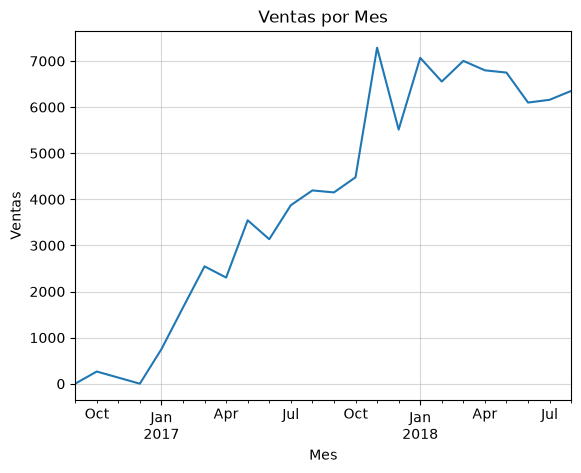

In [45]:
resultao.plot(kind = "line",
              title = "Ventas por Mes",
              xlabel = "Mes",
              ylabel = "Ventas")

plt.grid(alpha = 0.5)

# Barras horizontales: top 10 categorías por ingreso

* Merge order_items + products por product_id.
* groupby categoría → suma de price.
* Tomar las 10 mayores con .nlargest(10).
* Invertir el orden para que la mayor quede arriba y graficar con barh.

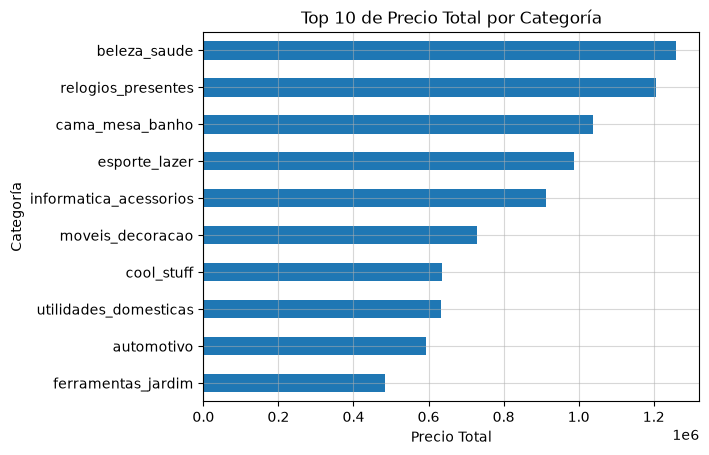

In [46]:
#2

df2_oi = order_items[["product_id","price"]]
df2_p = products[["product_id","product_category_name"]]
df_2 = df2_oi.merge(
    df2_p,
    on = "product_id",
    how = "left"
)

resultao2 = df_2.groupby("product_category_name")["price"].sum()
resultao2= resultao2.nlargest(10).sort_values()

resultao2.plot(kind = "barh",
              title = "Top 10 de Precio Total por Categoría",
              xlabel = "Precio Total",
              ylabel = "Categoría")

plt.grid(alpha = 0.5)

# Histograma: distribución del precio

* Usar order_items['price'].
* Primer histograma directo: se verá muy sesgado.
* Repetir con bins en escala log o con np.log10(price).
* Discusión: por qué la media engaña. Marcar media y mediana con axvline.

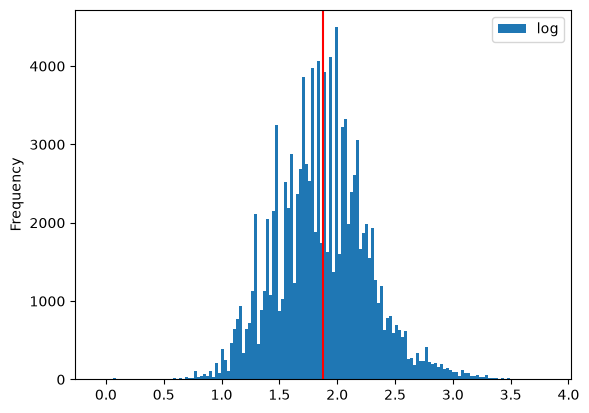

In [47]:
import numpy as np
df_3 = order_items
df_3["log"] = df_3["price"].apply(np.log10)

df_3["log"].plot(
    kind = "hist",
    bins = 150
)

media = df_3["log"].mean()
mediana = df_3["log"].median()

plt.axvline(media, color = "red")
plt.legend()
plt.show()

# Histograma comparativo: días de entrega reales vs. estimados
hist + alpha
En orders, convertir a datetime las columnas de compra, entrega real y entrega estimada.
Calcular dias_reales = entregado − compra y dias_estimados = estimado − compra (en .dt.days).
Eliminar NaN (pedidos no entregados).
Dos histogramas en el mismo eje con alpha=0.5 y leyenda.

<Axes: ylabel='Frequency'>

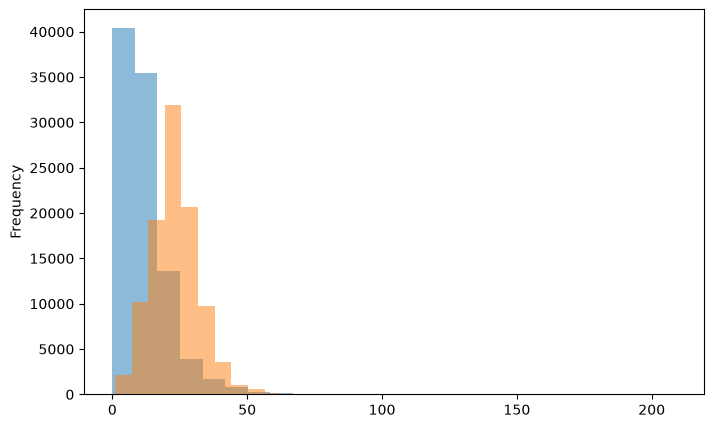

In [48]:
#4
df_4 = orders
df_4.dropna(subset = "order_estimated_delivery_date")
df_4 = df_4[["order_purchase_timestamp","order_delivered_customer_date","order_estimated_delivery_date"]]


df_4["dias_reales"] = (df_4["order_delivered_customer_date"] - df_4["order_purchase_timestamp"]).dt.days
df_4["dias_estimados"] = (df_4["order_estimated_delivery_date"] - df_4["order_purchase_timestamp"]).dt.days

lienzo, pintura = plt.subplots(figsize = (8,5))
df_4["dias_reales"].plot(
    kind = "hist",
    alpha = 0.5,
    bins = 25
)

df_4["dias_estimados"].plot(
    kind = "hist",
    alpha = 0.5,
    bins = 25
)


# Boxplot: calificación vs. días de retraso

* En orders, calcular retraso = entregado − estimado en días.
* Merge con order_reviews por order_id (quitar duplicados por order_id: hay pedidos con más de una reseña).
* Agrupar el retraso por review_score (1–5) → lista de 5 arrays.
* Pasar la lista a boxplot con etiquetas 1–5.
* Conclusión esperada: las calificaciones de 1 tienen retrasos mucho mayores

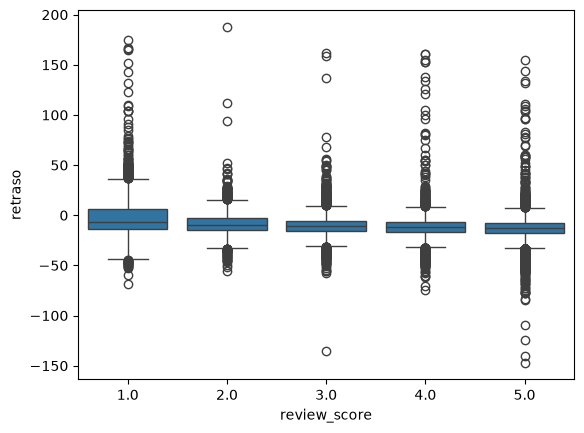

In [49]:
df_5 = orders
df_5 = df_5[["order_id","order_delivered_customer_date","order_estimated_delivery_date"]]

df_5["retraso"] = (df_5["order_delivered_customer_date"] - df_5["order_estimated_delivery_date"]).dt.days
df_5 = df_5.merge(
    order_reviews,
    on = "order_id",
    how = "left")
df_5 = df_5.drop_duplicates(subset = "order_id")

sns.boxplot(data = df_5, x = "review_score", y = "retraso")
plt.show()

# Barras con error: calificación promedio a tiempo vs. tarde

* Usar el mismo merge de la gráfica 5.
* Crear columna booleana tarde = retraso > 0.
* groupby('tarde') → mean y std de review_score.
* Graficar barras con yerr=std.

<Axes: xlabel='Tarde'>

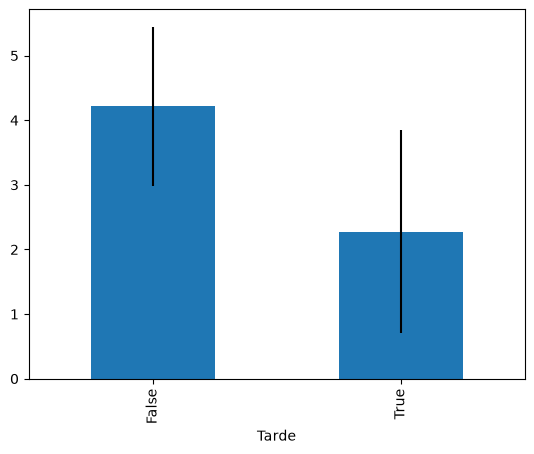

In [50]:
df_6 = orders[["order_id","order_delivered_customer_date","order_estimated_delivery_date"]]
df_6["retraso"] = (df_6["order_delivered_customer_date"] - df_6["order_estimated_delivery_date"]).dt.days
df_6 = df_6.merge(
    order_reviews,
    on = "order_id",
    how = "left")
df_6 = df_6.drop_duplicates(subset = "order_id")

df_6["Tarde"] = df_6["retraso"] > 0

grub_bai = df_6.groupby("Tarde")["review_score"].agg(["mean","std"])

grub_bai["mean"].plot(kind = "bar", yerr = grub_bai["std"])


In [51]:
df_6.head()

,order_id,order_delivered_customer_date,order_estimated_delivery_date,retraso,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,Tarde
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-10 21:25:13,2017-10-18,-8.0,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,False
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-07 15:27:45,2018-08-13,-6.0,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50,False
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-17 18:06:29,2018-09-04,-18.0,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58,False
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-02 00:28:42,2017-12-15,-13.0,359d03e676b3c069f62cadba8dd3f6e8,5.0,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03 00:00:00,2017-12-05 19:21:58,False
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-16 18:17:02,2018-02-26,-10.0,e50934924e227544ba8246aeb3770dd4,5.0,NaN,NaN,2018-02-17 00:00:00,2018-02-18 13:02:51,False


# Pastel / dona: métodos de pago

* order_payments → value_counts() de payment_type.
* Agrupar not_defined y categorías pequeñas en "otros".
* Graficar con autopct='%1.1f%%'; para dona, wedgeprops={'width':0.4}.
* Discusión: por qué los pasteles suelen ser mala idea; comparar con la versión en barras.

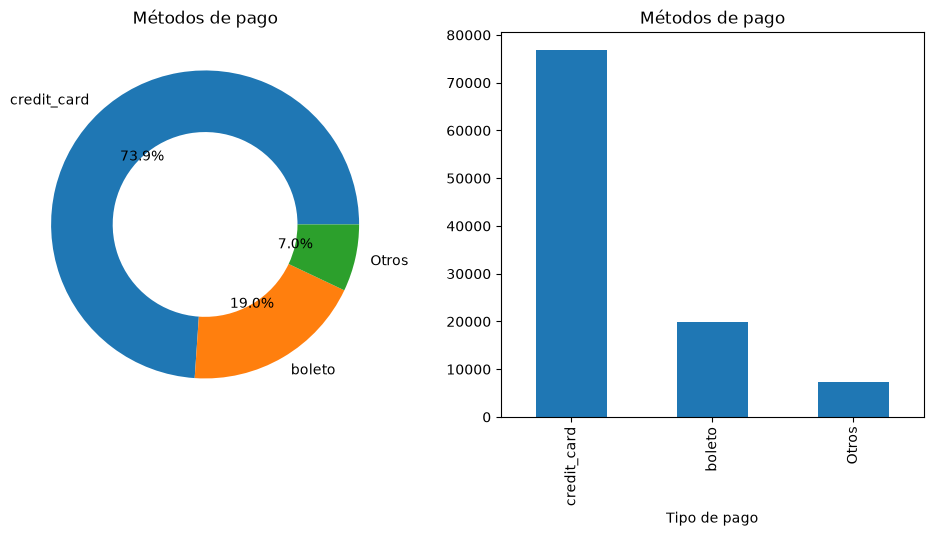

In [52]:
df7= payments
df7_top =  df7["payment_type"].value_counts().nlargest(2)
df7["otros"] = df7["payment_type"].apply(
    lambda x: x if x in df7_top else 'Otros'
)

fig , papu = plt.subplots(1, 2, figsize = (12,5))
otros = df7["otros"].value_counts()
ax= otros.plot(
    kind="pie",
    wedgeprops={'width':0.4},
    autopct='%1.1f%%',
    title="Métodos de pago",
    ax = papu[0]
)

ax2= otros.plot(
    kind="bar",
    xlabel="Tipo de pago",
    title="Métodos de pago",
    ax = papu[1]
)

# Barras agrupadas: monto promedio por mensualidades y método de pago

* Tomar order_payments.
* Crear rangos de payment_installments con pd.cut: 1, 2–3, 4–6, 7–10, más de 10.
* pivot_table: index = rango, columns = payment_type, values = payment_value, aggfunc = 'mean'.
* Barras agrupadas desplazando cada serie con x + i*ancho (o df.plot(kind='bar')).

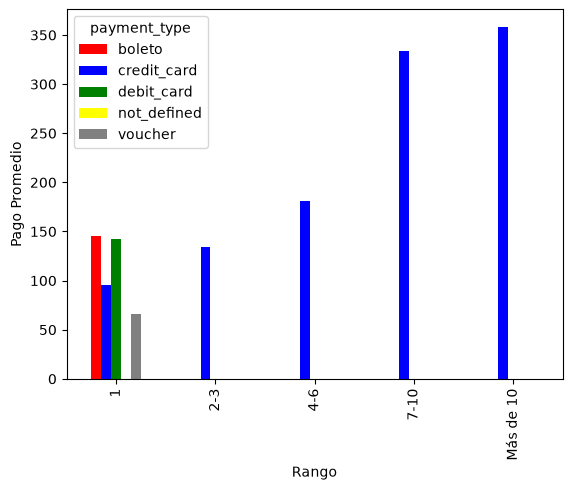

In [53]:
df_8 = payments
df_8["rango"] = pd.cut(payments["payment_installments"],
                       bins = [0,1,3,6,10,np.inf],
                       labels = ["1","2-3","4-6","7-10","Más de 10"])

papure = payments.pivot_table(index = "rango",
                              columns = "payment_type",
                              values = "payment_value",
                              aggfunc = "mean")

papure.plot(kind = "bar",
            xlabel = "Rango",
            ylabel = "Pago Promedio",
            color = ["red","blue","green","yellow","grey"])

plt.show()

# Barras apiladas: estado del pedido por estado de la república

* Merge orders + customers por customer_id.
* pivot_table: index = customer_state, columns = order_status, values = order_id, aggfunc = 'count', fill_value=0.
* Normalizar por fila (dividir entre .sum(axis=1)) para tener porcentajes.
* Quedarse con los 10 estados con más pedidos.
* Apilar barras con un loop acumulando bottom.

<Axes: xlabel='Estado de orden', ylabel='Proporcion de pedidos'>

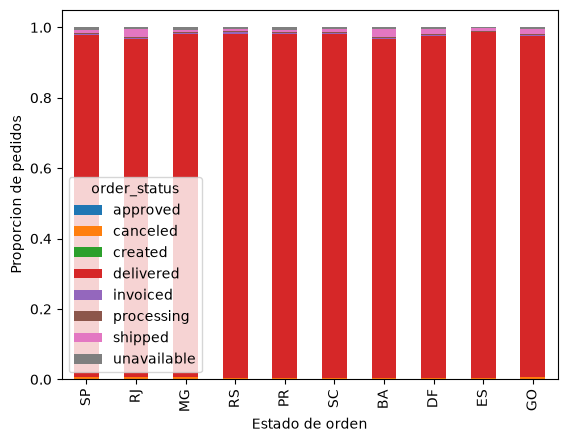

In [54]:
merge = orders.merge(customers, on="customer_id", how = "left")

papure_2 = merge.pivot_table(index = "customer_state",columns = "order_status",values= "order_id",aggfunc="count",fill_value=0)

papure_2_suma = papure_2.sum(axis=1)

papure_2_division = papure_2.div(papure_2_suma,axis=0)

papure_2_division_10 = papure_2_division.loc[papure_2_suma.nlargest(10).index]

papure_2_division_10.plot(kind="bar",
                         stacked="True",
                         xlabel="Estado de orden",
                         ylabel = "Proporcion de pedidos")

# Dispersión: peso del producto vs. costo de envío

* Merge order_items + products por product_id.
* Tomar product_weight_g y freight_value; quitar NaN.
* Muestrear con .sample(3000) (110k puntos saturan la gráfica).
* Graficar con alpha bajo; opcionalmente ejes en escala log.
* Extra: colorear por price con c= y agregar plt.colorbar().

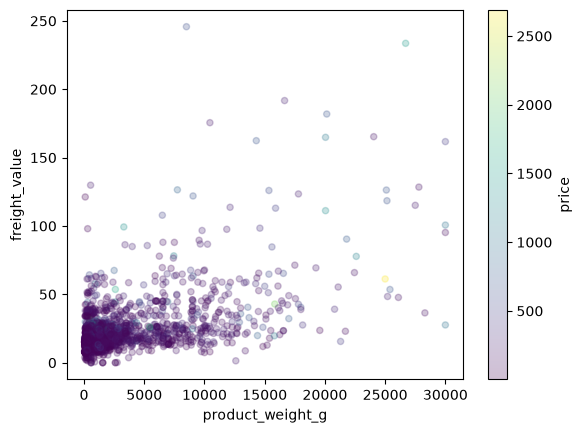

In [55]:
papure_3 = order_items.merge(products,on="product_id",how="left")

papure_3_no_vacios = papure_3[["product_weight_g","freight_value","price"]].dropna()

papure_3_sample = papure_3_no_vacios.sample(3000)

papure_3_sample.plot(kind="scatter",
                   x="product_weight_g",
                   y="freight_value",
                   c="price",
                   alpha = 0.25)
plt.show()

# Mapa de calor: pedidos por día de la semana × hora

* De order_purchase_timestamp extraer .dt.dayofweek y .dt.hour.
* pivot_table: index = día, columns = hora, values = order_id, aggfunc = 'count'.
* plt.imshow(pivot, aspect='auto', cmap='YlOrRd').
* Etiquetas Lun–Dom en y, 0–23 en x; agregar colorbar.
* Extra: escribir valores en las celdas con doble loop de ax.text.

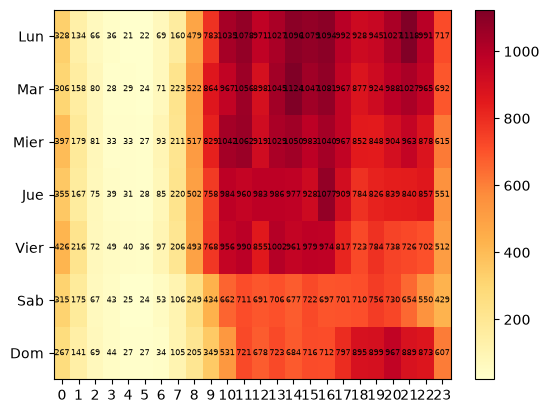

In [56]:
df_11 = orders
df_11["dias_semana"] = df_11["order_purchase_timestamp"].dt.dayofweek
df_11["horas"] = df_11["order_purchase_timestamp"].dt.hour
papure_4 =  df_11.pivot_table(index ="dias_semana", columns = "horas", values= "order_id",aggfunc="count")
mapa = plt.imshow(papure_4,aspect="auto",cmap ="YlOrRd" )
plt.yticks(range(7),["Lun","Mar","Mier","Jue","Vier","Sab","Dom"])
plt.xticks(range(24))
plt.colorbar(mapa)
for i in range(7):
    for j in range(24):
        plt.text(j, i, papure_4.iloc[i, j],  ha="center", va="center",fontsize=6)

# Dashboard final: subplots + doble eje

* Reutilizar los dataframes de las gráficas 1, 2, 5 y 11.
* fig, axes = plt.subplots(2, 2, figsize=(14,10)).
* Panel 1: pedidos por mes y, con twinx(), ingreso mensual en el segundo eje (merge orders + order_items, groupby mes, suma de price).
* Demás paneles: top categorías, boxplot de reseñas y heatmap.
* fig.suptitle, plt.tight_layout() y savefig('dashboard.png', dpi=150).

(Text(0.5, 0.98, 'Ejercicio 12'), None, None)

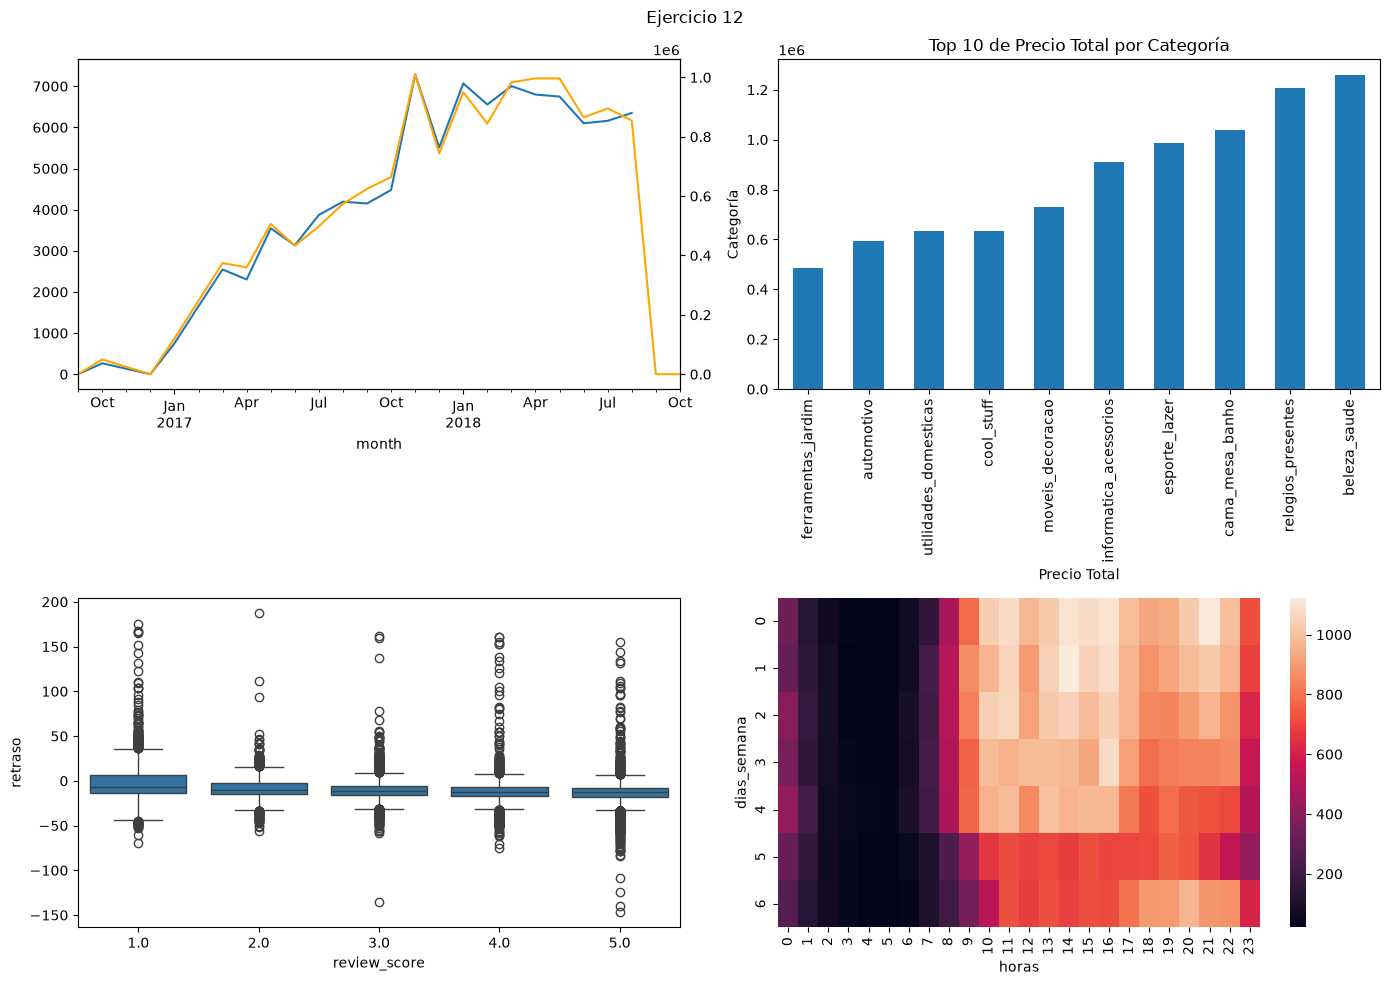

In [57]:
Uno = resultao

fig, papus = plt.subplots(2,2,figsize=(14,10))
Uno.plot(ax=papus[0,0])
ingreso_mensual = orders.merge(order_items, on = "order_id", how = "left")
ingreso_mensual["month"] = ingreso_mensual["order_purchase_timestamp"].dt.to_period('M')
ingreso = ingreso_mensual.groupby("month")["price"].sum()
ax2 = papus[0,0].twinx()
ingreso.plot(ax=ax2, color="orange")

resultao2.plot(kind = "bar",
              title = "Top 10 de Precio Total por Categoría",
              xlabel = "Precio Total",
              ylabel = "Categoría",
              ax = papus[0,1])

sns.boxplot(data = df_5, x = "review_score", y = "retraso", ax = papus[1,0])

sns.heatmap(papure_4,ax=papus[1,1])

fig.suptitle("Ejercicio 12"), plt.tight_layout(), plt.savefig('dashboard.png', dpi=150)


In [58]:
df_5.head()

,order_id,order_delivered_customer_date,order_estimated_delivery_date,retraso,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-10 21:25:13,2017-10-18,-8.0,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-07 15:27:45,2018-08-13,-6.0,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-17 18:06:29,2018-09-04,-18.0,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-02 00:28:42,2017-12-15,-13.0,359d03e676b3c069f62cadba8dd3f6e8,5.0,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03 00:00:00,2017-12-05 19:21:58
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-16 18:17:02,2018-02-26,-10.0,e50934924e227544ba8246aeb3770dd4,5.0,NaN,NaN,2018-02-17 00:00:00,2018-02-18 13:02:51
